# Kiểm thử phát âm và ngữ pháp trên dữ liệu công bố

500 audio SpeechOcean762 / 125 người nói và 200 câu mới FCE/JFLEG.
Notebook chỉ đọc kết quả đã lưu, không train hoặc gọi model/API.
Đây là đánh giá từng thành phần với reference có sẵn, chưa phải hội thoại đầu-cuối.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image, Audio
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/evaluate_extended_validation.py').is_file())
OUT = ROOT / 'data/generated/extended-validation-20261024'
read = lambda path: json.loads(Path(path).read_text(encoding='utf-8'))
summary = read(OUT / 'summary.json')
manifest = read(OUT / 'manifest.json')
report_manifest = read(OUT / 'report_manifest.json')
print(OUT / 'report.html')

D:\NCC\MDD\data\generated\extended-validation-20261024\report.html


## 1. Nguồn và checksum

SpeechOcean762 có 5 chuyên gia chấm mỗi mẫu. FCE lấy official test Cambridge/BEA-2019.
JFLEG lấy official test với nhiều reference. Loại source trùng train/validation và
lượt benchmark trước bằng chuẩn hóa lexical; không khẳng định loại được trùng nghĩa
hoặc biết hết dữ liệu pretraining của model nền.

In [2]:
checks = []
for name, expected in report_manifest['input_sha256'].items():
    with (ROOT / name).open('rb') as stream:
        checks.append({'file': name, 'matches': hashlib.file_digest(stream, 'sha256').hexdigest() == expected})
for name, expected in report_manifest['output_sha256'].items():
    with (OUT / name).open('rb') as stream:
        checks.append({'file': name, 'matches': hashlib.file_digest(stream, 'sha256').hexdigest() == expected})
assert all(row['matches'] for row in checks)
display(pd.DataFrame(checks))
print(json.dumps(manifest['grammar_selection'], ensure_ascii=False, indent=2))

,file,matches
0,data\generated\extended-validation-20261024\ma...,True
1,data\generated\extended-validation-20261024\gr...,True
2,data\generated\extended-validation-20261024\gr...,True
3,data\generated\extended-validation-20261024\gr...,True
4,data\generated\extended-validation-20261024\pr...,True
5,data\generated\extended-validation-20261024\pr...,True
6,scripts\report_extended_validation.py,True
7,scripts\score_extended_grammar_errant.py,True
8,grammar_cases.csv,True
9,grammar_metrics.png,True


{
  "selection": "100 FCE official-test + 100 unused JFLEG official-test; fixed SHA256 sort, no output/label-density selection",
  "fce_rows_with_unknown_edits_excluded": 195,
  "corpora": {
    "FCE": {
      "input_rows": 2500,
      "eligible": 2226,
      "excluded": {
        "duplicate_source": 221,
        "train_or_validation_exact_overlap": 53
      }
    },
    "JFLEG": {
      "input_rows": 747,
      "eligible": 647,
      "excluded": {
        "previous_benchmark_source_or_reference_overlap": 100
      }
    }
  },
  "zero_selected_source_overlap_with_training_or_validation": true,
  "zero_selected_source_overlap_with_previous_benchmark_sources_or_references": true,
  "exact_overlap_only": true
}


## 2. Phát âm SpeechOcean762

Gold: ít nhất 3/5 chuyên gia đánh dấu âm sai/thiếu. Accent score 1 được chấp nhận.
Canonical strict và demo CMU review là hai cách tạo gợi ý; đây không phải F1
cùng định nghĩa với L2-ARCTIC. Từ chưa quyết định không được coi là phát âm đúng.

,gold_correct_words,precision,recall_all_errors,false_positive_all_correct,recall_available,false_positive_available,coverage,f1_all
0,2954,0.143017,0.955224,0.519296,0.955224,0.522124,0.995034,0.248785


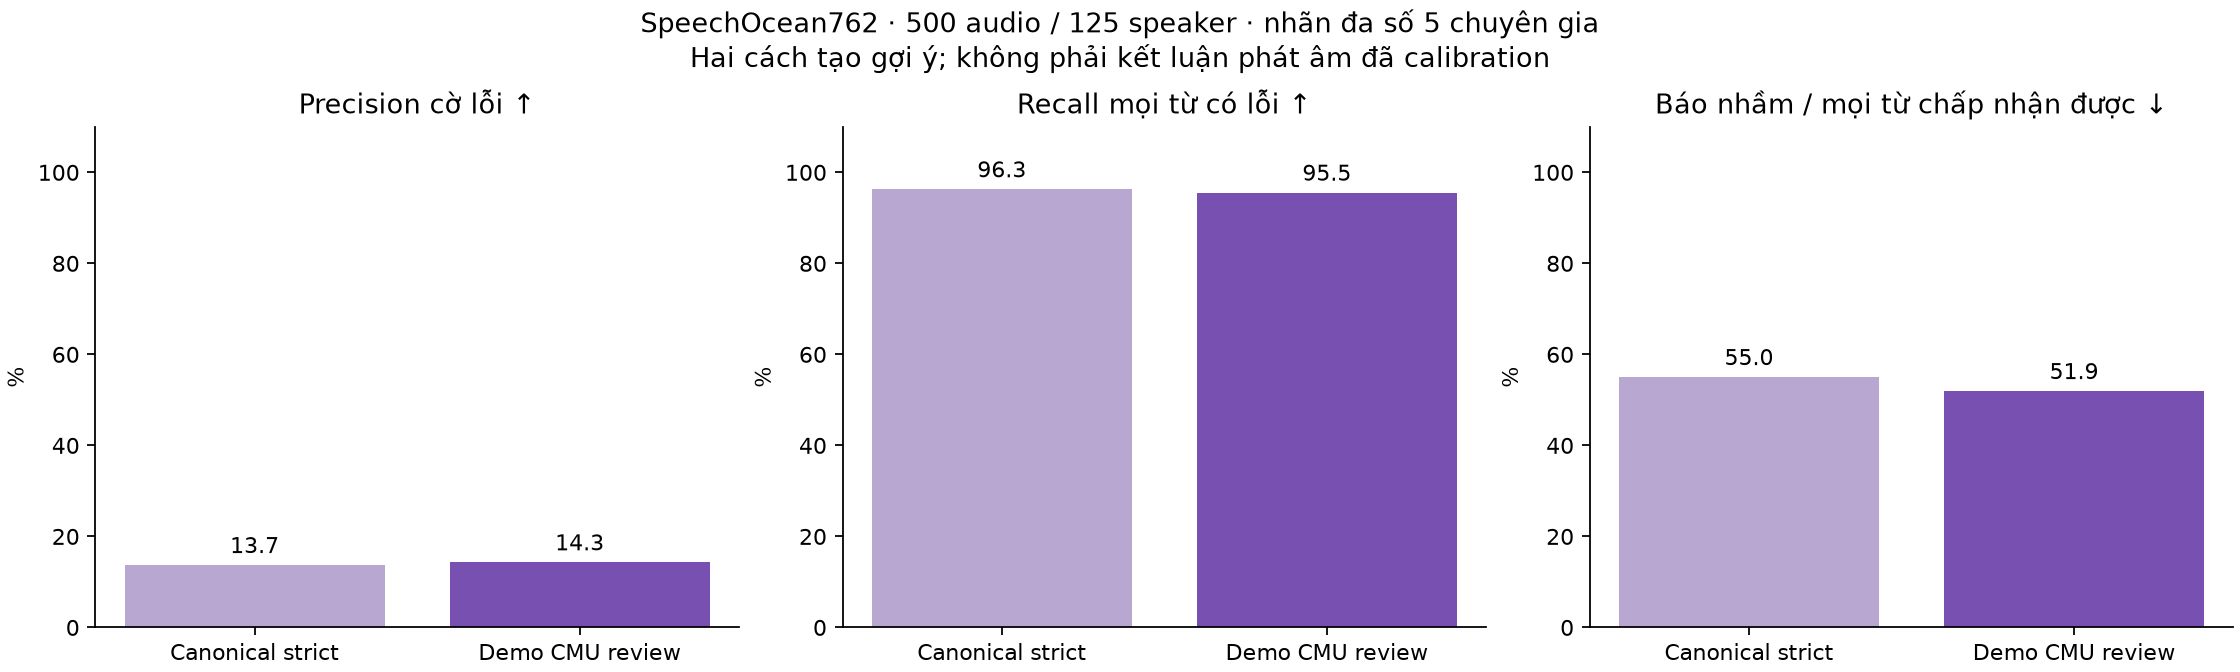

Gold word counts: {'tp': 256, 'fp': 1534, 'tn': 1404, 'fn': 12, 'unavailable_error_words': 0, 'unavailable_correct_words': 16, 'reference_words': 3222, 'gold_error_words': 268}
Approved categorical decisions: 0


In [3]:
p = summary['pronunciation']
display(pd.DataFrame([p['demo_review']]).drop(columns=['counts']))
display(Image(filename=str(OUT / 'pronunciation_metrics.png')))
print('Gold word counts:', p['demo_review']['counts'])
print('Approved categorical decisions:', p['calibrated_decisions'])

## 3. Nhóm tuổi, coverage và khoảng tin cậy

Corpus là tiếng Anh giọng Trung Quốc, không đại diện cho mọi giọng Việt.
Bootstrap lấy mẫu lại theo speaker để giữ tương quan giữa audio của cùng người.

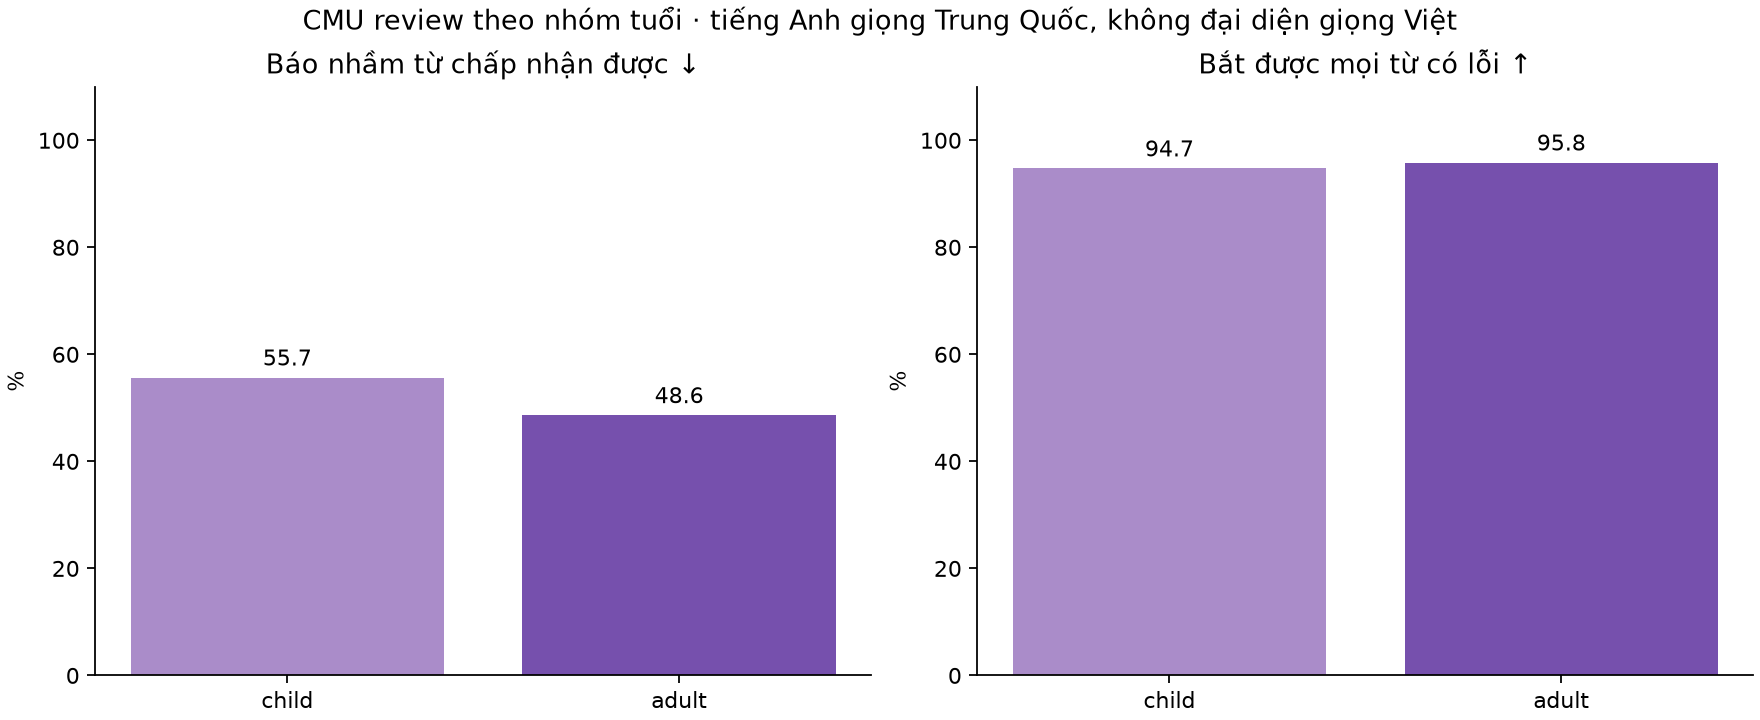

{
  "method": "speaker cluster bootstrap, 125 speakers, 2000 iterations, seed42; uncertainty within this corpus only",
  "fpr_all_correct_95": [
    0.4848865592866777,
    0.5528257126514602
  ],
  "recall_all_errors_95": [
    0.9270833333333334,
    0.9772748713550601
  ]
}
Word states: {'uncertain': 3206, 'unavailable': 16}


In [4]:
display(Image(filename=str(OUT / 'pronunciation_age.png')))
print(json.dumps(p['cluster_bootstrap'], ensure_ascii=False, indent=2))
print('Word states:', p['categorical_word_status'])

## 4. Ngữ pháp FCE và cách nói tự nhiên JFLEG

ERRANT 3.0.0 đo precision/recall/F0.5 edit trên FCE. GLEU/chrF là tương đồng
reference, không phải phần trăm câu đúng. All-row metrics dùng câu gốc làm fallback
khi không có gợi ý và báo riêng số đầu ra thực sự được hiển thị.

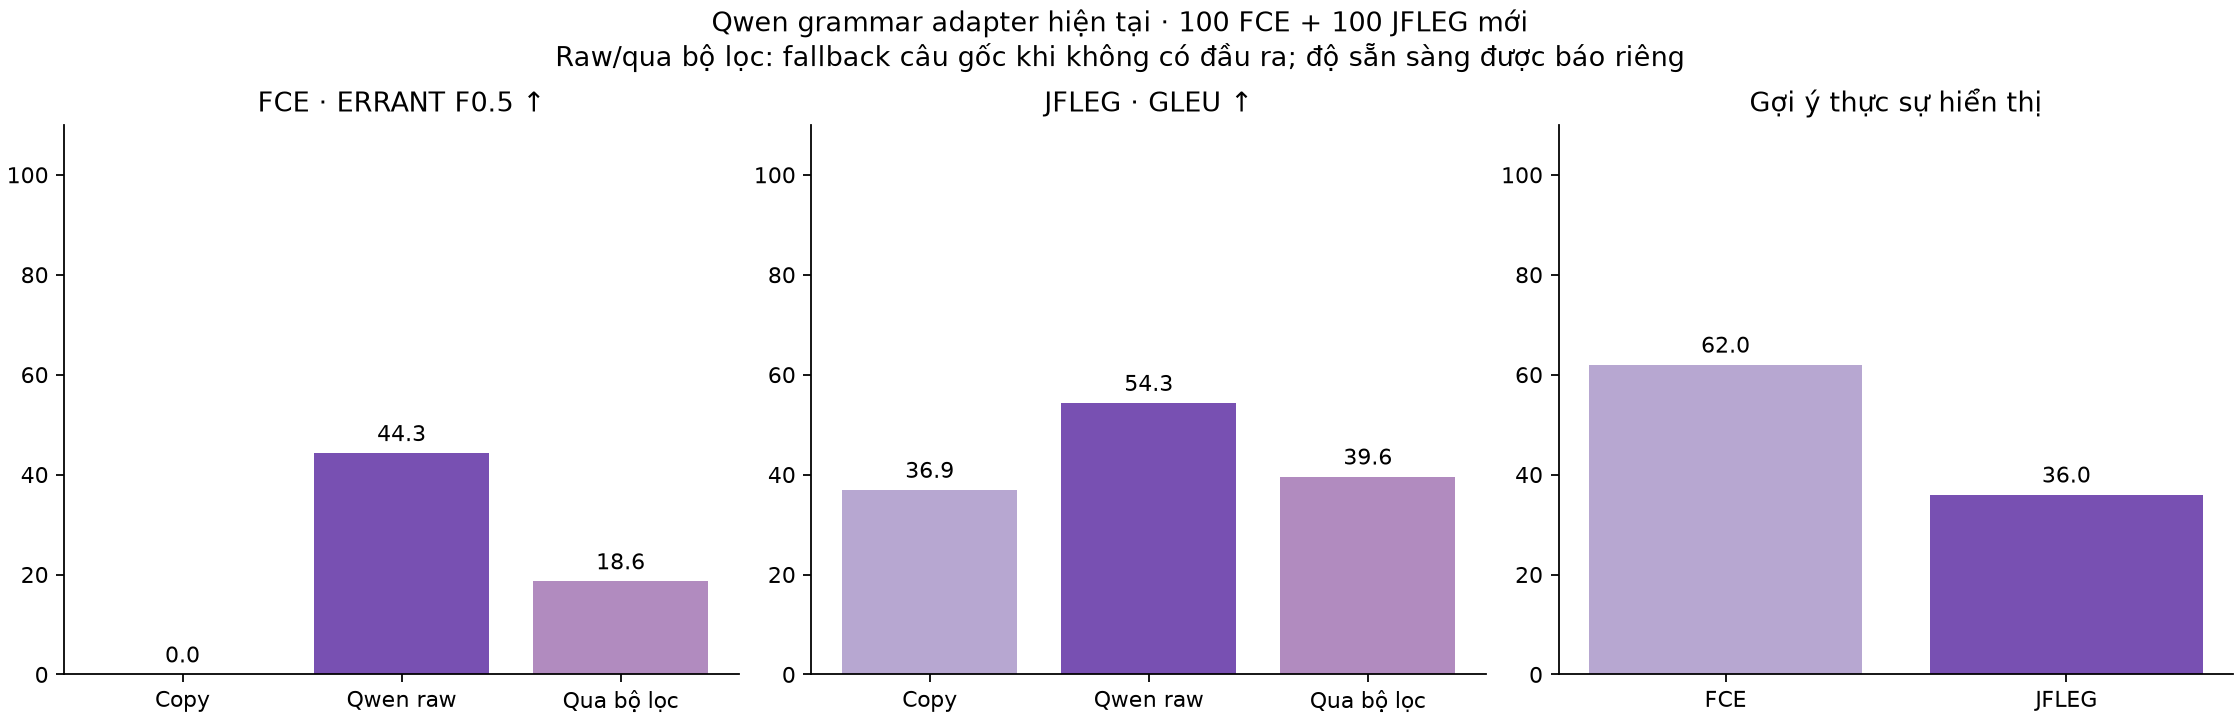

,corpus,output,GLEU,chrF,exact_ref,F0.5,shown
0,FCE,copy,55.9265,88.725256,0.28,0.0000,NaN
1,FCE,raw,68.5917,89.047062,0.34,0.4430,NaN
2,FCE,delivered,57.9309,88.775451,0.29,0.1864,62.0
3,JFLEG,copy,36.9395,90.639883,0.28,NaN,NaN
4,JFLEG,raw,54.3361,89.553202,0.35,NaN,NaN
5,JFLEG,delivered,39.6040,90.774609,0.28,NaN,36.0


In [5]:
display(Image(filename=str(OUT / 'grammar_metrics.png')))
metrics = []
for corpus, group in summary['grammar'].items():
    for arm in ('copy', 'raw', 'delivered'):
        text = group['text_similarity'][arm]
        metrics.append({'corpus': corpus, 'output': arm, 'GLEU': text['gleu']['score'],
            'chrF': text['chrf'], 'exact_ref': text['exact_reference_rate'],
            'F0.5': group.get('errant', {}).get(arm, {}).get('f05'),
            'shown': group['delivered'] if arm == 'delivered' else None})
display(pd.DataFrame(metrics))

## 5. Đầu ra thực tế từng câu

Giữ riêng câu model sinh và câu qua bộ lọc. Reference không được đưa cho model.
HTML có toàn bộ mẫu và chức năng tìm kiếm.

In [6]:
grammar = [json.loads(line) for line in (OUT / 'grammar/predictions.jsonl').read_text(encoding='utf-8').splitlines()]
display(pd.DataFrame([{key: row[key] for key in ('id', 'corpus', 'source', 'prediction', 'delivered_prediction', 'seconds')}
                      for row in grammar]).head(20))

,id,corpus,source,prediction,delivered_prediction,seconds
0,fce:test:988,FCE,"I, personally, couldn't live without the elect...","I, personally, couldn't live without electricity.","I, personally, couldn't live without electricity.",3.198220
1,fce:test:364,FCE,I hope that these informations will bring you ...,I hope that these informations will bring you ...,I hope that these informations will bring you ...,2.663590
2,fce:test:1250,FCE,"For example, in the past it would had been ext...","For example, in the past, it would have been e...",None,4.852932
3,fce:test:650,FCE,"As now I'm being away from home, telephone is ...","Now I'm away from home, telephone is very impo...",None,2.254409
4,fce:test:368,FCE,Your group has been booked into Palace Hotel w...,"Your group has been booked into Palace Hotel, ...","Your group has been booked into Palace Hotel, ...",2.952622
5,fce:test:121,FCE,You only have to take the subway - train.,You only have to take the subway - train.,You only have to take the subway - train.,1.842520
6,fce:test:1898,FCE,What are you going to do without phone?,What are you going to do without a phone?,What are you going to do without a phone?,1.877222
7,fce:test:1917,FCE,My fair Mobile Phone.,My fair mobile phone.,My fair mobile phone.,1.304439
8,fce:test:331,FCE,Because there are so many unique shops and you...,Because there are so many unique shops and you...,Because there are so many unique shops and you...,2.618280
9,fce:test:796,FCE,I am looking forward to see you soon.,I am looking forward to seeing you soon.,I am looking forward to seeing you soon.,1.799352


## 6. Nghe mẫu có nhãn chuyên gia

Hai ví dụ lấy theo thứ tự đã khóa: một audio mọi chuyên gia chấm hoàn hảo,
một audio có từ lỗi theo đa số. Ví dụ minh họa không thay đổi metric.

In [7]:
pronunciation = [json.loads(line) for line in (OUT / 'pronunciation/predictions.jsonl').read_text(encoding='utf-8').splitlines()]
examples = [next(r for r in pronunciation if r['human']['strict_perfect']),
            next(r for r in pronunciation if any(r['human']['majority_word_error']))]
for row in examples:
    print(row['utterance_id'], row['human']['reference_text'])
    print('Gold error words:', [w for w,e in zip(row['human']['words'], row['human']['majority_word_error']) if e])
    print('Review hints:', [w['text'] for w in row['sound_candidates']['words']])
    display(Audio(filename=row['audio_path']))

000940012

 LILLY IS GOING TO SEE ZEBRA
Gold error words: []
Review hints: ['LILLY', 'ZEBRA']


000440104 LISA LAYLA GOT THE BOOTS
Gold error words: ['LISA', 'LAYLA']
Review hints: ['LISA', 'LAYLA', 'GOT', 'THE', 'BOOTS']


## Nguồn và giới hạn

- [SpeechOcean762, Interspeech 2021](https://www.isca-archive.org/interspeech_2021/zhang21x_interspeech.html)
- [FCE/Cambridge và BEA-2019](https://www.cl.cam.ac.uk/research/nl/bea2019st/)
- [FCE, ACL 2011](https://aclanthology.org/P11-1019/)
- [JFLEG, EACL 2017](https://aclanthology.org/E17-2037/)
- [ERRANT của tác giả](https://github.com/chrisjbryant/errant)

Không thay ngưỡng/prompt/bộ lọc dựa vào test mới. Chưa có đánh giá con người
về giữ nghĩa, tính tự nhiên hoặc hội thoại. Dữ liệu viết/đọc có sẵn không thay thế
kiểm thử hội thoại tự do trên nhiều người Việt.